In [41]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/dataset.txt        


In [42]:
with open("data/dataset.txt", "r") as file:
    data = file.read().split("\n")

In [43]:
import pandas as pd
import numpy as np


labels = list(map(lambda x: list(map(lambda y: y[len('__label__'):], x.split(" ")[0].split(","))), data))
comments = list(map(lambda x: " ".join(x.split(" ")[1:]), data))

In [44]:
df = pd.DataFrame(np.array([labels, comments], dtype="object").T, columns = ["labels", "comment"])
df.head(5)

,labels,comment
0,[INSULT],скотина! что сказать
1,[NORMAL],я сегодня проезжала по рабочей и между домами ...
2,[NORMAL],очередной лохотрон. зачем придумывать очередно...
3,[NORMAL],"ретро дежавю ... сложно понять чужое сердце , ..."
4,[NORMAL],а когда мы статус агрогородка получили?


In [45]:
df.describe()

,labels,comment
count,248291,248291
unique,9,248291
top,[NORMAL],скотина! что сказать
freq,203685,1


In [46]:
df.isnull().sum()

,0
labels,0
comment,0


In [47]:
df.astype(str).duplicated().sum()

0

In [48]:
df[(df['labels'].apply(len) == 0)]

,labels,comment


In [49]:
empty_objects = df[(df['labels'].apply(lambda x: '' in x)) | (df['comment'] == '')].index
empty_objects

Index([248290], dtype='int64')

In [50]:
df = df.drop(empty_objects)

Дальше мы можем посмотреть на данные как хотел автор ( с классификацией ), а можем сделать target бинарным, где NORMAL будет считаться, как не токсичный комментарий. Давайте для начала посмотрим на данные с несколькими классами

Давайте убедимся, что нету rows, где есть несколько labels и NORMAL

In [51]:
df[(df['labels'].apply(len) > 1) & (df['labels'].apply(lambda x: 'NORMAL' in x))]

,labels,comment


Почистим теперь данные от различных ссылок, знаков препинания, стопслов и прочего.

Вопрос что делать с эмодзи. Мы можем переводить их в английские слова. Однако, не можем в русские. Поскольку мы анализируем русские комментарии, то, возможно, имеет смысл отбросить тогда эмодзи. С другой стороны нужно тестировать и, возможно, если удалить все англоязычные слова и оставить только англоязычное представление эмодзи, то у нас получится хороший результат. Напишем две функции, где одна удаляет эмодзи, а другая превращает в англоязычные слова. Для примера пока возьмем перевод в англоязычные слова.

In [52]:
%pip install emoji

import re
import emoji
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize


nltk.download('stopwords')
nltk.download('punkt')

def clean_text(text):
  res = text.lower()

  # удалим все, что не относится к русским словам
  res = re.sub('[^а-яА-ЯёЁ\s]', '', res)

  # удалим лишние пробельные символы
  res = re.sub('\s+', ' ', res)

  # Заменяем эмодзи на английские слова
  res = emojis_words(res)

  # Стоп-слова: удаление стоп-слов - это стандартная практика очистки текстов
  res = remove_stopwords(res, [])

  return res

def remove_stopwords(text, l):
  stop_words = set(stopwords.words("russian") + l)
  tokens = word_tokenize(text)
  tokens = [token for token in tokens if token not in stop_words]
  res = ' '.join(tokens)

  return res

def emojis_words(text):
  res = emoji.demojize(text, delimiters=(" ", " "))
  res = res.replace(":", "").replace("_", " ")
  return res

def remove_emojis(text):
  return emoji.replace_emoji(text, replace="")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [53]:
df['comment'] = df['comment'].apply(clean_text)
df.head(5)

,labels,comment
0,[INSULT],скотина сказать
1,[NORMAL],сегодня проезжала рабочей домами снитенко гомо...
2,[NORMAL],очередной лохотрон придумывать очередной налог...
3,[NORMAL],ретро дежавю сложно понять чужое сердце лиш ощ...
4,[NORMAL],статус агрогородка получили


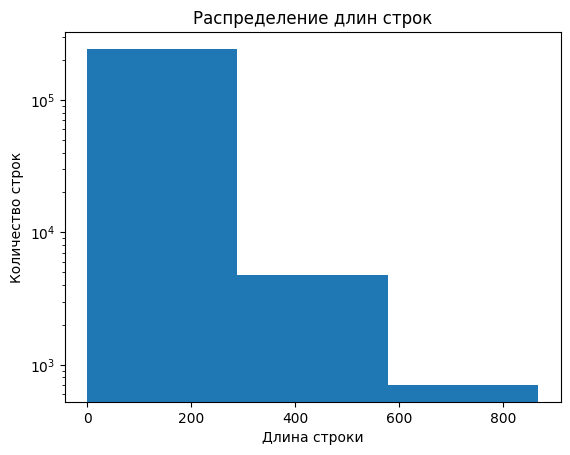

In [54]:
import matplotlib.pyplot as plt


plt.hist(df['comment'].str.len(), bins=3)
plt.xlabel('Длина строки')
plt.ylabel('Количество строк')
plt.title('Распределение длин строк')
plt.yscale('log')
plt.show()

Видно, что здесь есть довольно мало длинных комментариев. Возможно, их имеет смысл удалить, но я бы попробовал с ними и без. Тем более 800 символов с пробелами это не очень много ( для комментария может и много, но для постов допустим не сильно )

Теперь мы можем смело разделять df по классам с explode(), чтобы было удобнее работать с колонкой labels. Сделаю тут же еще df_bin, где будем смотреть не на labels, а на отдельную колонку toxic

In [55]:
df_class = df.explode('labels')

In [56]:
df_class['labels'].unique()

array(['INSULT', 'NORMAL', 'THREAT', 'OBSCENITY'], dtype=object)

In [57]:
df_class.describe()

,labels,comment
count,256799,256799
unique,4,235203
top,NORMAL,
freq,203685,856


In [58]:
df_bin = df.copy()

In [59]:
df_bin['toxic'] = df_bin['labels'].apply(lambda x: 'NORMAL' not in x)
df_bin.describe()

,labels,comment,toxic
count,248290,248290,248290
unique,8,235203,2
top,[NORMAL],,False
freq,203685,856,203685


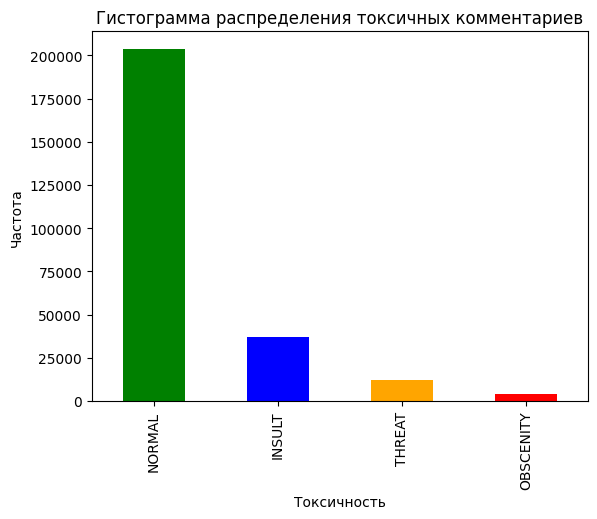

In [60]:
df_class['labels'].value_counts().plot(kind='bar', color=['green', 'blue', 'orange', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

Для наглядности посмотрим что происходит в бинарном случае

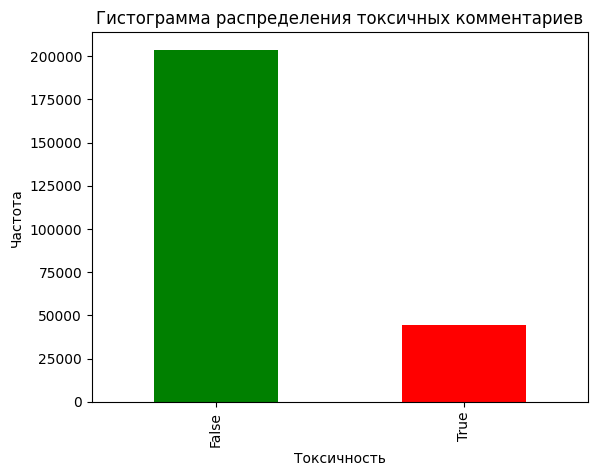

In [61]:
df_bin['toxic'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

Теперь посмотрим на частотный анализ слов. Также на частотный анализ слов с лемматизацией и стеммингом

[('это', 28115), ('очень', 8712), ('просто', 6021), ('ещё', 5770), ('спасибо', 5299), ('всё', 5297), ('тебе', 4674), ('всем', 4227), ('лет', 4179), ('люди', 4017)]


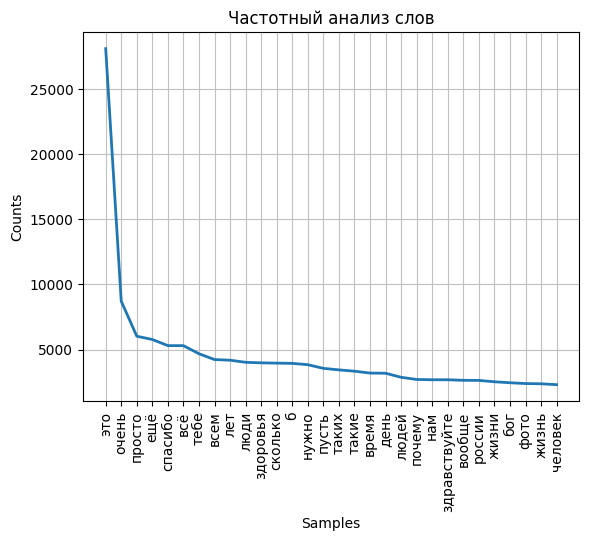

<Axes: title={'center': 'Частотный анализ слов'}, xlabel='Samples', ylabel='Counts'>

In [62]:
from nltk.probability import FreqDist


comments = " ".join(df['comment'].tolist())
comments_tokens = word_tokenize(comments)
text = nltk.Text(comments_tokens)
f_dist = FreqDist(text)
print(f_dist.most_common(10))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов')

Видно, что здесь остались еще шумные слова, которые нам не помогут. Например, 'это' и 'очень'. Давайте тоже их исключим.

In [63]:
stop_words = ['это', 'очень']
df['comment'] = df['comment'].apply(remove_stopwords, args=(stop_words,))

[('просто', 6021), ('ещё', 5770), ('спасибо', 5299), ('всё', 5297), ('тебе', 4674), ('всем', 4227), ('лет', 4179), ('люди', 4017), ('здоровья', 3977), ('сколько', 3954)]


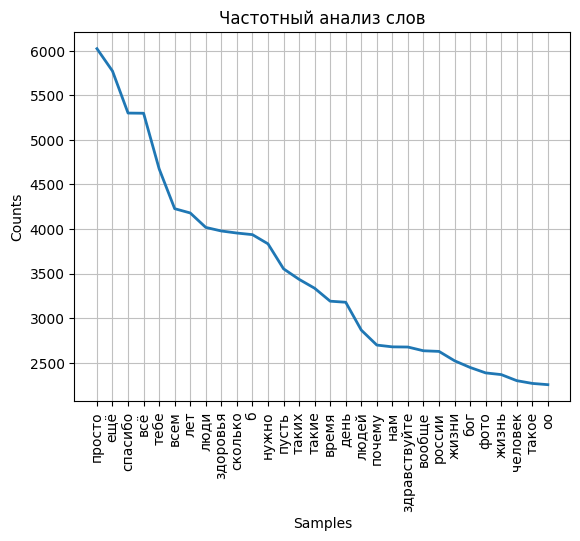

<Axes: title={'center': 'Частотный анализ слов'}, xlabel='Samples', ylabel='Counts'>

In [64]:
from nltk.probability import FreqDist


comments = " ".join(df['comment'].tolist())
comments_tokens = word_tokenize(comments)
text = nltk.Text(comments_tokens)
f_dist = FreqDist(text)
print(f_dist.most_common(10))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов')

Есть еще всякие 'б', 'оо'. Давайте сначала глянем на стемминг и лемматизацию

('так', 16168)
('сво', 10558)
('люд', 8523)
('сам', 8038)
('прост', 7980)
('наш', 6946)
('все', 6315)
('здоров', 6187)
('эт', 6153)
('нужн', 6140)


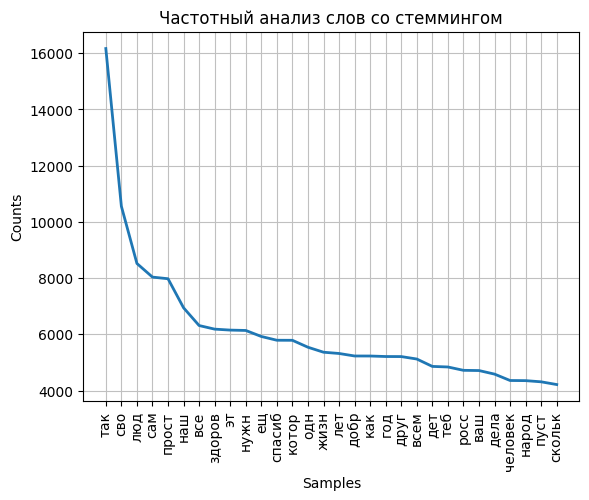

<Axes: title={'center': 'Частотный анализ слов со стеммингом'}, xlabel='Samples', ylabel='Counts'>

In [40]:
# Стемминг
from nltk.stem.snowball import SnowballStemmer


snow_stemmer = SnowballStemmer(language='russian')
text_stemmed = map(lambda word: snow_stemmer.stem(word), text)
f_dist = FreqDist(text_stemmed)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов со стеммингом')

Применили стемминг и видно, что всяких 'б' и 'оо' уже нет. Давайте еще глянем на лемматизацию

In [65]:
!pip install pymorphy2
import pymorphy2

('такой', 15388)
('человек', 12353)
('свой', 10411)
('год', 9256)
('весь', 7737)
('день', 7193)
('быть', 6859)
('наш', 6814)
('ребёнок', 6810)
('просто', 6021)


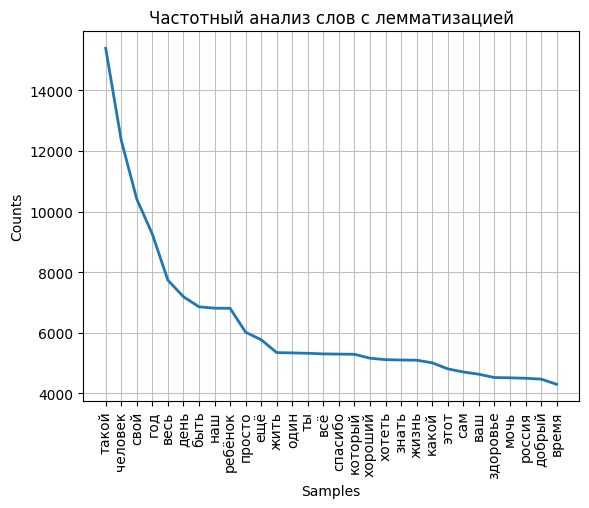

<Axes: title={'center': 'Частотный анализ слов с лемматизацией'}, xlabel='Samples', ylabel='Counts'>

In [66]:
# Лемматизация
morph = pymorphy2.MorphAnalyzer()

text_lemmatized = map(lambda word: morph.parse(word)[0].normal_form, text)
f_dist = FreqDist(text_lemmatized)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов с лемматизацией')

Есть небольшая разница. Список у лемматизации на самом деле более интересный, что логично. В принципе, 6 минут на 248к комментов не очень долго для нас. Тем более, что мы целимся на комменты в соцсети, что необязательно иметь мгновенный отклик. Вот если целить на стримы, то там желательно быстро реагировать. Там можно было бы взять стемминг.

In [67]:
df['tokenized'] = df['comment'].str.split()

In [68]:
df['comment_lemmatized'] = df['tokenized'].apply(lambda words: [morph.parse(word)[0].normal_form for word in words])

In [69]:
df['comment_lemmatized'].head(5)

,comment_lemmatized
0,"[скотина, сказать]"
1,"[сегодня, проезжать, рабочий, дом, снитенко, г..."
2,"[очередной, лохотрон, придумывать, очередной, ..."
3,"[ретро, дежавю, сложно, понять, чужое, сердце,..."
4,"[статус, агрогородок, получить]"


('день рождение', 1620)
('дать бог', 1336)
('добрый день', 853)
('сей пора', 581)
('сколько стоить', 562)
('друг друг', 557)
('бог здоровье', 520)
('добрый утро', 515)
('операция мск', 504)
('каждый день', 495)


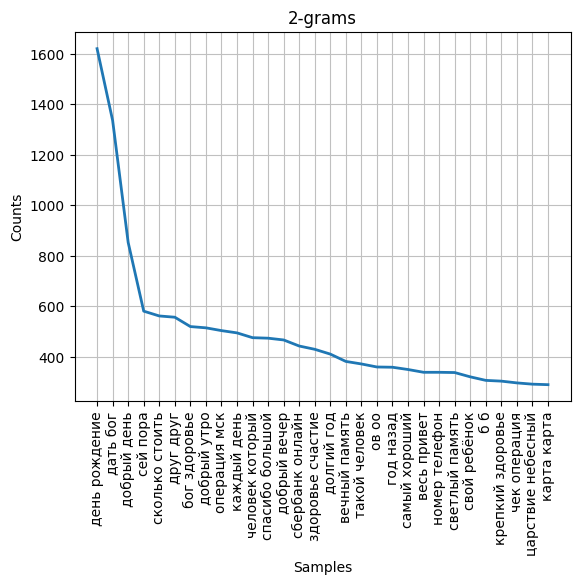

<Axes: title={'center': '2-grams'}, xlabel='Samples', ylabel='Counts'>

In [70]:
from nltk.util import ngrams
from functools import reduce

df['2-grams'] = df['comment_lemmatized'].apply(lambda row: [' '.join(grams) for grams in ngrams(row, 2)])
bigrams = [item for sublist in df['2-grams'] for item in sublist]
f_dist = FreqDist(bigrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='2-grams')

('дать бог здоровье', 451)
('чек операция сбербанк', 255)
('малый дело важный', 198)
('дело важный нужно', 198)
('дружеский хватать хозяйство', 197)
('хватать хозяйство вещь', 197)
('хозяйство вещь малый', 197)
('вещь малый дело', 197)
('нужный вещь редкий', 197)
('вещь редкий хватать', 197)


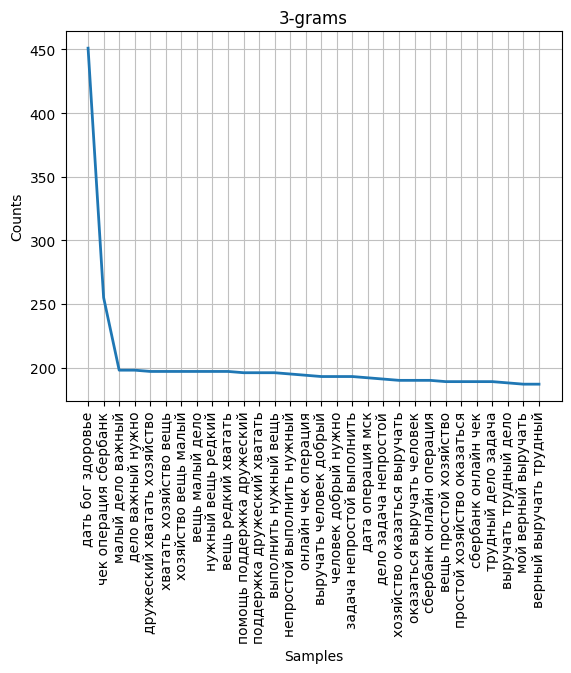

<Axes: title={'center': '3-grams'}, xlabel='Samples', ylabel='Counts'>

In [71]:
df['3-grams'] = df['comment_lemmatized'].apply(lambda row: [' '.join(grams) for grams in ngrams(row, 3)])
threegrams = [item for sublist in df['3-grams'] for item in sublist]
f_dist = FreqDist(threegrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='3-grams')

In [72]:
text_lemmatized = ' '.join([word for comment in df['comment_lemmatized'] for word in comment])

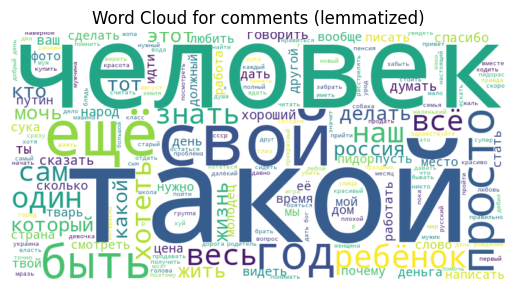

In [76]:
from wordcloud import WordCloud


wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(text_lemmatized)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for comments (lemmatized)')
plt.show()

In [78]:
text_lemmatized = ' '.join([word for comment in df[df_bin['toxic']]['comment_lemmatized'] for word in comment])

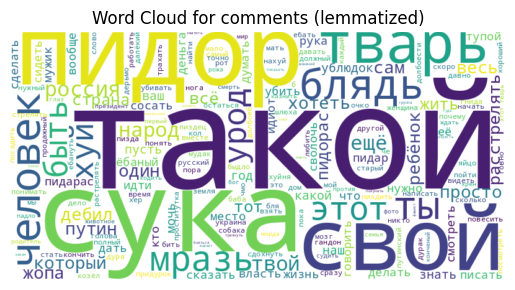

In [79]:
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(text_lemmatized)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments (lemmatized)')
plt.show()

Датасет довольно большой, что довольно хорошо при обучении. Хорошо, что есть классификация, что дает возможность использовать его под разные задачи. Можно еще поэкспериментировать при построении модельки со стопсловами. Например, меня
тут смущают слова 'такой' и 'свой'. Их можно попробовать добавить в стопслова после леммитизации. Word Cloud для токсичных комментариев выглядит довольно хорошо. Действительно, есть много токсичных слов. В датасете так же есть эмодзи, которые, возможно, будут тоже полезны при построении модели.